# Ноутбук 1. Слой лосса: CCE против альтернатив на T4

Воспроизведение «Cut Your Losses in Large-Vocabulary Language Models» (Wijmans и др., ICLR 2025, arXiv 2411.09009v2).

Условия: Tesla T4, fp16, torch 2.5.1 / Triton 3.1 (отдельное окружение), Qwen2.5-0.5B-Instruct на Alpaca.
Числа статьи получены на A100 в bf16 для Gemma 2 2B: сравниваются отношения, а не абсолютные значения.

Запуск: выполнить ячейки по порядку (на Kaggle должен быть включён Internet). Код клонируется из репозитория https://github.com/SaylesMand/Efficient-Models-HWs (папка `hw2/`), окружение ставит `hw2/scripts/setup_oldstack.sh`.
Результаты пишутся построчно в `results_loss_layer/` рядом с репозиторием: после обрыва сессии достаточно перезапустить ячейку. В конце они упаковываются в `results_loss_layer.zip`. Результаты прогона, по которому написаны выводы ниже, лежат в репозитории в `hw2/results/`.

In [1]:
!nvidia-smi

Fri Oct  9 08:50:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Подготовка

In [ ]:
import os, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SaylesMand/Efficient-Models-HWs"
WORK = Path("/kaggle/working" if os.path.exists("/kaggle/working") else "/content")
REPO = WORK / "Efficient-Models-HWs"
if (REPO / ".git").exists():
    subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
HW2 = REPO / "hw2"
# в hw2/results лежит прогон, по которому написаны выводы; новый прогон пишется отдельно
RES = WORK / "results_loss_layer"
RES.mkdir(parents=True, exist_ok=True)

os.environ["HW2"] = str(HW2)
os.environ["PYTHONPATH"] = str(HW2 / "src")
os.environ["CCE_RESULTS"] = str(RES)
os.environ["VENV"] = str(WORK / "venv_old")
PY = os.environ["PY"] = str(WORK / "venv_old" / "bin" / "python")
print("HW2 =", HW2, "| результаты:", RES)

In [3]:
!bash $HW2/scripts/setup_oldstack.sh

torch 2.5.1+cu121 | triton 3.1.0 | transformers 4.48.2 | Tesla T4


In [ ]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = RES
jl = lambda exp, f="measurements.jsonl": pd.read_json(R / exp / f, lines=True)

def summary(exp, f="measurements.jsonl", by=("method", "kind")):
    """среднее и разброс по повторам: память MiB, время ms"""
    return jl(exp, f).groupby(list(by))[["mem_mib", "runtime_ms"]].agg(["mean", "std"]).round(1)

## 1.0 Окружение, смоук-тест, форма блоков

**Статья.** Раздел не проверяет утверждение статьи, а готовит условия для остальных. Ядра CCE у авторов настроены на A100: блок 128x128 и 4 стадии конвейера. Такому блоку нужно больше shared memory, чем 64 КБ на T4.

**Что делается.** 
1. Окружение: версии библиотек и GPU.
2. Смоук-тест: `cce` в fp16 на малых тензорах сверяется с `F.cross_entropy` по критерию из тестов авторов.
3. Кэш эмбеддингов: 40 960 токенов ответа и 40 960 токенов вместе с промптом (для 1.1 и 1.4).
4. Форма блоков: 24 формы, B ∈ {32, 64, 128} × V ∈ {32, 64, 128, 256} × варпы {4, 8}. Для каждой проверяется, компилируется ли она в 64 КБ shared memory, совпадают ли лосс и градиенты с fp32-эталоном, и замеряется время Loss+Gradient при N = 8192. Самая быстрая корректная форма используется во всех следующих разделах.

In [5]:
!cd $HW2 && $PY -m cce_repro.run setup

===== setup =====
Эмбеддинги: Qwen/Qwen2.5-0.5B-Instruct, 40960 токенов, keep_invalids=False, бэкбон torch.float32
tokenizer_config.json: 7.30kB [00:00, 33.1MB/s]
vocab.json: 2.78MB [00:00, 111MB/s]
merges.txt: 1.67MB [00:00, 139MB/s]
tokenizer.json: 7.03MB [00:00, 192MB/s]
config.json: 100%|████████████████████████████| 659/659 [00:00<00:00, 3.86MB/s]
model.safetensors: 100%|█████████████████████| 988M/988M [00:02<00:00, 438MB/s]
generation_config.json: 100%|█████████████████| 242/242 [00:00<00:00, 1.58MB/s]
README.md: 11.6kB [00:00, 43.6MB/s]
alpaca_data_cleaned.json: 100%|███████████| 44.3M/44.3M [00:00<00:00, 99.6MB/s]
Generating train split: 100%|██| 51760/51760 [00:00<00:00, 90268.38 examples/s]
Эмбеддинги: Qwen/Qwen2.5-0.5B-Instruct, 40960 токенов, keep_invalids=True, бэкбон torch.float32
   b32_v32_w4: 1209.9 ms, ok=True
   b32_v32_w8: 1406.8 ms, ok=True
   b32_v64_w4: 868.4 ms, ok=True
   b32_v64_w8: 954.3 ms, ok=True
   b32_v128_w4: 710.2 ms, ok=True
   b32_v128_w8: 744.2 ms,

In [6]:
display(jl("setup", "smoke.jsonl").pivot_table(index=["shape", "method"], columns="tensor", values="frac_violations"))
g = jl("setup", "grid.jsonl")
display(g[[c for c in ["name", "ok", "fwbw_ms", "mem_mib", "cos_dE", "cos_dC", "loss_abs_err", "kernels", "error"] if c in g]]
        .sort_values("fwbw_ms"))
print(json.load(open(R / "cce_config.json")))

tensor                          dC   dE  loss
shape           method                       
(252, 507, 497) cce            0.0  0.0   0.0
                cce_exact      0.0  0.0   0.0
                torch_compile  0.0  0.0   0.0
(256, 512, 512) cce            0.0  0.0   0.0
                cce_exact      0.0  0.0   0.0
                torch_compile  0.0  0.0   0.0

,name,ok,fwbw_ms,mem_mib,cos_dE,cos_dC,loss_abs_err,kernels,error
10,b64_v64_w4,True,553.418524,275.258301,0.999723,0.999997,0.000118,"{'fw': [{'n_regs': 128, 'n_spills': 0, 'shared...",NaN
19,b128_v64_w8,True,558.879657,275.258301,0.999723,0.999997,0.000118,"{'fw': [{'n_regs': 128, 'n_spills': 0, 'shared...",NaN
13,b64_v128_w8,True,560.281805,275.258301,0.999767,0.999996,0.000067,"{'fw': [{'n_regs': 128, 'n_spills': 0, 'shared...",NaN
18,b128_v64_w4,True,564.835828,275.258301,0.999723,0.999997,0.000118,"{'fw': [{'n_regs': 230, 'n_spills': 0, 'shared...",NaN
12,b64_v128_w4,True,576.109509,275.258301,0.999767,0.999996,0.000067,"{'fw': [{'n_regs': 168, 'n_spills': 0, 'shared...",NaN
16,b128_v32_w4,True,582.485638,275.258301,0.999689,0.999997,0.000186,"{'fw': [{'n_regs': 255, 'n_spills': 20, 'share...",NaN
11,b64_v64_w8,True,654.119666,275.258301,0.999723,0.999996,0.000118,"{'fw': [{'n_regs': 80, 'n_spills': 0, 'shared'...",NaN
17,b128_v32_w8,True,706.514490,275.258301,0.999689,0.999997,0.000186,"{'fw': [{'n_regs': 80, 'n_spills': 0, 'shared'...",NaN
4,b32_v128_w4,True,710.171179,275.258301,0.999767,0.999996,0.000067,"{'fw': [{'n_regs': 124, 'n_spills': 0, 'shared...",NaN
8,b64_v32_w4,True,714.020813,275.258301,0.999689,0.999997,0.000186,"{'fw': [{'n_regs': 80, 'n_spills': 0, 'shared'...",NaN


{'name': 'b64_v64_w4', 'BLOCK_B': 64, 'BLOCK_V': 64, 'BLOCK_D': 32, 'num_warps': 4, 'num_stages': 2, 'fwbw_ms_N8192': 553.4185241699219}


**Сравнение со статьёй и вывод 1.0.**

| | статья | T4 |
|---|---|---|
| форма блока | 128x128x32, 4 стадии (A100) | 64x64x32, 2 стадии, 4 варпа |
| shared memory формы 128x128 | помещается в 164 КБ A100 | 83 968 Б при лимите 65 536 Б: не компилируется |
| тензорные ядра в ядрах CCE | да | да: mma в fw 32, в bw 160 (Triton 3.1) |

1. Окружение: Tesla T4 (sm_75, 40 SM, 14 912 MiB), Python 3.11, torch 2.5.1, Triton 3.1, transformers 4.48.2, liger-kernel 0.5.10, cut-cross-entropy 25.9.3 (коммит 3de376c).
2. Смоук-тест: доля нарушений критерия авторов 0 у `cce`, `cce_exact`, `torch_compile` на обеих формах тензоров, для loss, dE и dC.
3. Кэш эмбеддингов: 40 960 токенов ответа (304 примера) и 40 960 токенов вместе с промптом (232 примера, из них 27.2% с меткой -100); нечисловых значений нет.
4. Форма блоков: из 24 форм 18 компилируются и проходят проверку (|dloss| < 1e-2, косинус dE и dC > 0.999); 6 не помещаются в shared memory, среди них авторская 128x128. Выбрана b64_v64_w4: 553.4 ms при N = 8192. Пять лучших форм в пределах 4.1% (553-576 ms), поэтому выбор формы на выводы ниже не влияет.

Вывод: CCE на T4 работает только с уменьшенной формой блока; дальнейшие замеры идут на ней.

## 1.1 Корректность

**Статья.** «In practice, this leads to a 3.5x speedup without loss of precision in any gradient computation.» (раздел 4.3)

**Что делается.** 
1. Критерий из [`tests/test_cce_loss_backward.py`](https://github.com/apple-aiml-research/ml-cross-entropy/blob/main/tests/test_cce_loss_backward.py): |gt - x| ≤ |gt - ref| + 1e-3 поэлементно, где gt - расчёт в fp32, ref - обычный PyTorch в fp16, x - проверяемый метод. Проверяются loss, dE и dC у 9 методов (все варианты CCE и torch.compile) на трёх формах из тестов авторов, с игнорируемыми токенами и без, и на реальных эмбеддингах с промптом (N = 2048).
2. Точность против fp32 на реальных эмбеддингах: относительная ошибка и косинус dE и dC.
3. `shift=1` на входе (B, T, D) против ручного сдвига.
4. Детерминизм: совпадают ли loss, dE и dC побитово в трёх одинаковых запусках `cce`.

In [7]:
!cd $HW2 && $PY -m cce_repro.run correctness

===== correctness =====
===== correctness: done


In [8]:
c = jl("correctness", "checks.jsonl")
display(c.groupby(["case", "method"]).frac_violations.max().unstack())  # 0: условие авторов выполнено
display(c[c.case == "qwen_alpaca_2048"].pivot_table(index="method", columns="tensor", values=["cosine", "rel_err"]))
display(jl("correctness", "extra.jsonl"))

method,cce,cce_eps_bf16,cce_exact,cce_kahan,cce_kahan_full_c,cce_kahan_full_e,cce_no_filter,cce_no_sort,torch_compile
case,,,,,,,,,
qwen_alpaca_2048,0,0,0,0,0,0,0,0,0
random_252x507x497,0,0,0,0,0,0,0,0,0
random_252x507x497_ign,0,0,0,0,0,0,0,0,0
random_252x507x512,0,0,0,0,0,0,0,0,0
random_252x507x512_ign,0,0,0,0,0,0,0,0,0
random_256x512x512,0,0,0,0,0,0,0,0,0
random_256x512x512_ign,0,0,0,0,0,0,0,0,0


cosine             rel_err                    
tensor                  dC        dE        dC        dE      loss
method                                                            
cce               0.999997  0.999809  0.002247  0.019536  0.000044
cce_eps_bf16      0.999997  0.999809  0.002409  0.019536  0.000044
cce_exact         0.999997  0.999754  0.002188  0.022198  0.000044
cce_kahan         0.999998  0.999809  0.002183  0.019536  0.000044
cce_kahan_full_c  0.999997  0.999809  0.002187  0.019536  0.000044
cce_kahan_full_e  0.999998  0.999809  0.002184  0.019536  0.000044
cce_no_filter     0.999997  0.999754  0.002263  0.022199  0.000044
cce_no_sort       0.999997  0.999754  0.002260  0.022198  0.000044
torch_compile     0.999997  0.999953  0.002220  0.009751  0.000038

,check,shift_vs_manual,shift_vs_fp32,loss_equal,dE_equal,dC_equal,dC_max_diff,dC_rel_diff
0,shift,0.0,0.000018,NaN,NaN,NaN,NaN,NaN
1,determinism,NaN,NaN,1.0,0.0,0.0,0.001221,0.000602


**Сравнение со статьёй и вывод 1.1.**

| | статья | T4 |
|---|---|---|
| точность градиентов | «without loss of precision in any gradient computation» (из статьи) | условие авторов выполнено в 63 из 63 случаев (9 методов x 7 случаев) |
| относительная ошибка dE против fp32, реальные данные | - | CCE 1.95%, cce_exact 2.22%, torch.compile 0.98% |
| относительная ошибка dC против fp32 | - | 0.22-0.24% у всех |
| лосс против fp32 | - | 4.4e-5 у всех вариантов CCE |

1. Критерий авторов выполнен в 63 из 63 случаев (9 методов x 7 случаев).
2. Точность против fp32: ошибка dE у `cce` 1.95%, у `cce_exact` и `cce_no_filter` 2.22%, у torch.compile 0.98%; ошибка dC 0.22-0.24% у всех. Фильтрация градиента точность не ухудшает: ошибка dE у `cce` не больше, чем без фильтрации.
3. `shift=1` совпадает с ручным сдвигом побитово (разница 0).
4. Детерминизм неполный: при трёх одинаковых запусках loss совпадает побитово, а dE и dC различаются; разброс dC до 6.0e-4 (относительно нормы). Вероятная причина: порядок накопления через атомарные операции и спин-блокировки. Статья детерминизм не заявляет.

Вывод: утверждение о точности воспроизводится в смысле тестов авторов; ошибка dE у CCE в fp16 примерно вдвое выше, чем у torch.compile, но в пределах критерия.

## 1.2 Таблица 1

**Статья.** Таблица 1 (Gemma 2 2B, N = 8192, A100): память и время для Loss, Gradient, Loss+Gradient у 10 методов. Строки Loss+Gradient: CCE 1 164 MB / 145 ms, torch.compile 16 000 MB / 143 ms, baseline 28 000 MB / 208 ms. «CCE reduces the memory footprint of the loss computation from 24 GB to 1 MB, and the total training-time memory consumption of the classifier head from 28 GB to 1 GB.» (аннотация)

**Что делается.** 
1. Те же 10 методов, что в таблице 1, в трёх режимах: Loss, Gradient, Loss+Gradient. Liger, как в статье, только в режиме Loss+Gradient. N = 8192, 5 непересекающихся окон токенов.
2. Память сравнивается с нижней границей, то есть с размером ∇E и ∇C в fp16 (расчёт): (8192 + 151 936) · 896 · 2 Б = 273.7 MiB. Критерии: память CCE в пределах 1% от нижней границы; Kahan-варианты около 2 × нижняя граница; порядок методов по памяти совпадает со статьёй.
3. Время сравнивается отношениями к torch.compile.

In [9]:
!cd $HW2 && $PY -m cce_repro.run table1

===== table1 =====
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      fw       198.5 ms       0.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      bw       363.3 ms     274.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      fwbw     570.0 ms     275.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 liger                    fwbw     681.8 ms     319.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              fw       140.2 ms    2374.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              bw       198.1 ms     540.9 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              fwbw     329.5 ms    2670.8 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            fw       129.1 ms    2374.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            bw       184.5 ms    2618.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            fwbw     316.3 ms    4748.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 base

In [10]:
display(summary("table1").unstack("kind"))

mem_mib                                    runtime_ms         \
                    mean                      std                 mean          
kind                  bw       fw     fwbw     bw   fw fwbw         bw     fw   
method                                                                          
baseline          9496.0  11870.0  14244.0    0.0  0.0  0.0      291.3  215.3   
cce                274.6      0.6    275.3    0.0  0.0  0.0      364.1  198.8   
cce_kahan          548.6      0.6    549.3    0.0  0.0  0.0      435.4  198.5   
cce_kahan_full_c   548.6      0.6    549.3    0.0  0.0  0.0      671.0  198.8   
cce_kahan_full_e   548.6      0.6    549.3    0.0  0.0  0.0      645.5  199.0   
cce_no_filter      274.1      0.1    274.1    0.0  0.0  0.0      647.3  192.4   
cce_no_sort        274.1      0.6    274.7    0.0  0.0  0.0      409.3  200.1   
liger                NaN      NaN    312.8    NaN  NaN  3.6        NaN    NaN   
torch_compile     2422.8   2374.1   4748.1  109.2  0.0  0.0      189.1  131.5   
torchtune_8        345.6   2374.1   2670.8  109.2  0.0  0.0      200.6  142.3   

                                          
                          std             
kind               fwbw    bw   fw  fwbw  
method                                    
baseline          522.5   1.6  0.4   2.3  
cce               562.8   9.4  0.2  10.3  
cce_kahan         632.9  14.1  0.2  14.2  
cce_kahan_full_c  867.2   7.7  0.1   6.8  
cce_kahan_full_e  842.0   7.2  0.2   6.9  
cce_no_filter     835.2   0.8  0.2   1.0  
cce_no_sort       605.1  12.0  1.0  12.0  
liger             681.0   NaN  NaN   0.5  
torch_compile     320.1   2.6  1.4   2.2  
torchtune_8       334.0   1.4  1.2   2.5

**Сравнение со статьёй и вывод 1.2.** Статья: Gemma 2 2B, A100, bf16 (из статьи). Воспроизведение: Qwen2.5-0.5B, T4, fp16, среднее по 5 окнам. Отношения посчитаны по колонке Loss+Gradient.

| метод | статья: память / нижн. граница | T4 | статья: время / torch.compile | T4 |
|---|---|---|---|---|
| CCE | 1.003 | 1.006 | 1.01 | 1.76 |
| Liger | 1.27 | 1.14 | 2.13 | 2.13 |
| torchtune, 8 чанков | 8.3 | 9.8 | 1.18 | 1.04 |
| torch.compile | 13.8 | 17.4 | 1.00 | 1.00 |
| baseline | 24.1 | 52.1 | 1.45 | 1.63 |
| CCE без сортировки | 1.001 | 1.004 | 1.11 | 1.89 |
| CCE без фильтрации | 1.001 | 1.002 | 2.50 | 2.61 |
| CCE-Kahan | 2.003 | 2.007 | 1.12 | 1.98 |
| CCE-Kahan-FullC | 2.003 | 2.007 | 2.19 | 2.71 |
| CCE-Kahan-FullE | 2.003 | 2.007 | 2.04 | 2.63 |

1. Абсолютные значения на T4: CCE 275.3 MiB / 562.8 ms (нижняя граница 273.7 MiB, расчёт); torch.compile 4 748 MiB / 320.1 ms; baseline 14 244 MiB / 522.5 ms. Только лосс: CCE 0.6 MiB против 11 870 MiB у baseline (в статье 1 MB против 24 000 MB, из статьи).
2. Память:
   - память CCE в пределах 1% от нижней границы: выполнен (+0.59%);
   - Kahan-варианты около 2 x нижняя граница: выполнен (2.01);
   - порядок методов по памяти совпадает: выполнен (ранговая корреляция 1.00);
   - отношение памяти baseline к нижней границе на T4 больше (52 против 24): логиты занимают N·|V|, а нижняя граница (N + |V|)·D. У Qwen2.5-0.5B размерность D = 896 в 2.6 раза меньше, чем у Gemma 2 2B (расчёт);
   - абсолютная память, зависящая только от N и |V|, совпадает со строками Qwen 2.5 (7B) из таблицы A3 (тот же словарь Qwen, |V| = 152 064 против 151 936 у Qwen2.5-0.5B; там «MB» фактически MiB): только лосс у baseline 11 880 против 11 870 MiB, у torch.compile 2 376 против 2 374, у чанков 2 379 против 2 374; Loss+Gradient у baseline 14 256 против 14 244 (из статьи / T4). Разница равна отношению словарей (0.9992). Не совпадает torch.compile Loss+Gradient: 9 504 в статье против 4 748 на T4, вероятно из-за разных версий PyTorch (2.4.1 против 2.5.1), это не проверялось.
3. Время:
   - у методов без CCE отношения к torch.compile близки к статье: Liger 2.13 против 2.13, чанки 1.04 против 1.18, baseline 1.63 против 1.45;
   - CCE на T4 в 1.76 раза медленнее torch.compile, в статье паритет. Отставание есть уже в прямом проходе (198.8 против 131.5 ms; в статье 46 против 49 ms, из статьи). Значит, дело в ядрах Triton на sm_75 с блоком 64x64 и двумя стадиями против cuBLAS, а не в самом алгоритме;
   - Кэхэн: CCE-Kahan медленнее CCE в 1.12 раза по Loss+Gradient (в статье 1.10).

Повторный прогон на Colab (другая T4, те же версии) дал ту же память и те же отношения времени в пределах 0.12 (у CCE 1.79), а абсолютные времена на 3-6% меньше.

Вывод: экономия памяти воспроизводится количественно (CCE у нижней границы, у Kahan-вариантов 2x, тот же порядок методов). Паритет по скорости с torch.compile на T4 не воспроизводится: CCE медленнее в 1.8 раза.

## 1.3 Разреженность softmax и фильтрация

**Статья.** «by the ∼50th most likely token, the probability has fallen bellow our threshold for gradient filtering» (раздел 5.2); «less than 0.02% of elements are non-zero» (раздел 4.3). Таблица 1, Gradient / Loss+Gradient: CCE 100 / 145 ms, без сортировки (строка 6) 115 / 159 ms, без фильтрации (строка 7) 314 / 357 ms.

**Что делается.** 
1. Аналог рисунка 3: средняя вероятность токена в зависимости от его ранга и ранг, на котором она падает ниже порога 2⁻¹² (bf16, статья) и 2⁻¹⁵ (fp16, `auto` в воспроизведении). Критерий: ранг пересечения 2⁻¹² в 30-100.
2. Доля ненулевых элементов |S - onehot| (не ниже порога), где S - softmax. Критерий: 0.01-0.04%.
3. Доля блоков выбранной формы, которые пропускает фильтр, с сортировкой словаря и без.
4. Время и ошибка градиента при разных порогах; замедления абляций без фильтрации и без сортировки берутся из 1.2. Критерий: направление эффектов фильтрации и сортировки совпадает со статьёй.

In [11]:
!cd $HW2 && $PY -m cce_repro.run sparsity

===== sparsity =====
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      bw       353.0 ms     274.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      fwbw     558.7 ms     275.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_eps_bf16             bw       285.3 ms     274.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_eps_bf16             fwbw     479.7 ms     275.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_no_filter            bw       646.8 ms     274.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_no_filter            fwbw     832.5 ms     274.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_no_sort              bw       397.2 ms     274.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_no_sort              fwbw     593.9 ms     274.7 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_exact                bw       861.7 ms     548.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce_exact                fwbw    1054.9 ms     548.1 MiB
   Qwen2.5-0.5B-Instruct rep1 N=8192 cc

{'N': 8192, 'block': [64, 64], 'rank_below_bf16': 54, 'rank_below_fp16': 183, 'prob_at_rank': {'1': 0.6864205963083805, '2': 0.11909568114710785, '5': 0.01777820957643781, '10': 0.0047661913930901415, '50': 0.0002771077278067962, '100': 8.437195930812643e-05, '1000': 1.4918991172066188e-06, '10000': 1.3739567915745299e-08, '100000': 2.6949344048146423e-11}, 'blocks_skipped_sorted_bf16': 0.8453658119208087, 'nonzero_bf16': 0.00025869721410248396, 'blocks_skipped_sorted_fp16': 0.6950459403959562, 'nonzero_fp16': 0.0007962569933331304, 'blocks_skipped_unsorted_bf16': 0.7662667175652906, 'blocks_skipped_unsorted_fp16': 0.5764466617523167}


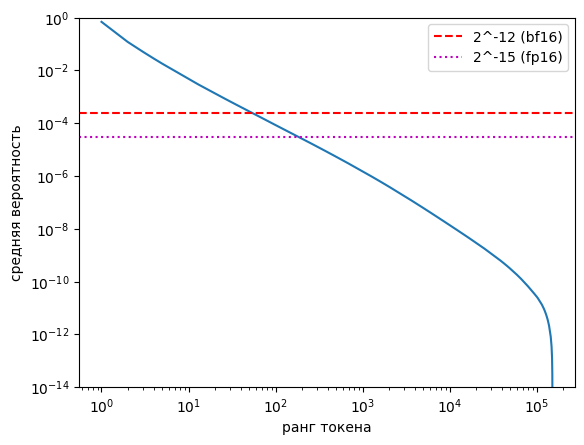

mem_mib                  runtime_ms                    
                 mean         std            mean           std      
kind               bw   fwbw   bw fwbw         bw    fwbw    bw  fwbw
method                                                               
cce             274.6  275.3  0.0  0.0      363.9   563.4  14.2  11.5
cce_eps_bf16    274.6  275.3  0.0  0.0      286.3   482.3   5.3   5.7
cce_exact       548.1  548.1  0.0  0.0      861.5  1053.1   0.6   1.9
cce_no_filter   274.1  274.1  0.0  0.0      647.5   835.4   0.7   2.5
cce_no_sort     274.1  274.7  0.0  0.0      410.1   606.1  13.0  12.7

,method,dE_rel_err,dE_max_abs,dE_cos,dE_rows_zeroed,dC_rel_err,dC_max_abs,dC_cos,dC_rows_zeroed
0,cce,0.031196,5.364418e-07,0.999513,0.000488,0.001150,0.000244,0.999999,0
1,cce_eps_bf16,0.031196,5.364418e-07,0.999513,0.000488,0.001195,0.000488,0.999999,0
2,cce_no_filter,0.000382,5.960464e-08,1.000000,0.000000,0.001158,0.000488,0.999999,0
3,cce_no_sort,0.000446,5.960464e-08,1.000000,0.000122,0.001235,0.000488,0.999999,0


In [12]:
print(json.load(open(R / "sparsity" / "stats.json")))
curve = np.load(R / "sparsity" / "curve.npy")
plt.loglog(np.arange(1, len(curve) + 1), np.maximum(curve, 1e-30))
plt.axhline(2**-12, color="r", ls="--", label="2^-12 (bf16)")
plt.axhline(2**-15, color="m", ls=":", label="2^-15 (fp16)")
plt.ylim(1e-14, 1); plt.xlabel("ранг токена"); plt.ylabel("средняя вероятность"); plt.legend(); plt.show()
display(summary("sparsity", "timing.jsonl").unstack("kind"))
display(jl("sparsity", "grad_error.jsonl"))

**Сравнение со статьёй и вывод 1.3.**

| | статья (из статьи) | T4 |
|---|---|---|
| ранг, где средняя вероятность падает ниже 2^-12 | ~50 | 54 |
| доля ненулевых \|S - onehot\| >= 2^-12 | < 0.02% | 0.026% |
| то же при пороге fp16 2^-15 (`auto` в воспроизведении) | - | ранг 183, 0.080% |
| без фильтрации / CCE, Gradient | 3.14 | 1.78 |
| без фильтрации / CCE, Loss+Gradient | 2.46 | 1.48 |
| без сортировки / CCE, Gradient | 1.15 | 1.12 |
| без сортировки / CCE, Loss+Gradient | 1.10 | 1.08 |

Значения статьи взяты из таблицы 1 (строки 1, 6, 7).

1. Ранг пересечения 2^-12: 54 (в статье ~50), критерий в 30-100 выполнен. При пороге fp16 2^-15 ранг 183.
2. Доля ненулевых при 2^-12: 0.026% (в статье < 0.02%), критерий 0.01-0.04% выполнен. При 2^-15: 0.080%.
3. Пропускаемые блоки 64x64 (доля от всех):

| порог | с сортировкой | без сортировки |
|---|---|---|
| 2^-12 (bf16) | 84.5% | 76.6% |
| 2^-15 (fp16, `auto`) | 69.5% | 57.6% |

4. Время и точность при разных порогах (bw / fwbw, ms):
   - `cce` (2^-15): 364 / 563;
   - `cce_eps_bf16` (2^-12): 286 / 482;
   - без фильтрации: 648 / 835;
   - `cce_exact`: 862 / 1 053.

   Относительная ошибка dE против `cce_exact` одинакова при обоих порогах (3.12%). Направление эффектов фильтрации и сортировки совпадает со статьёй: критерий выполнен.

Вывод: разреженность softmax воспроизводится почти количественно. Эффект сортировки совпадает со статьёй (1.12 против 1.15). Эффект фильтрации тот же по направлению, но слабее (1.78 против 3.14). Причина в пороге: в fp16 `auto` даёт 2^-15, и пропускается 69.5% блоков, а не 84.5%. С порогом статьи 2^-12 без фильтрации медленнее в 648 / 286 = 2.26 раза (расчёт), при той же ошибке градиента.

## 1.4 Удаление игнорируемых токенов (таблица A1)

**Статья.** «CCE (and other methods) can be made up to 3 times faster by removing tokens that are ignored.» (раздел 5.1); «This represents a significant speed up for all methods but Liger Kernels.» (приложение B)

**Что делается.** 
1. Данные с промптом, N = 8192. В данных игнорируется около 26% токенов (без паддинга), поэтому потолок ускорения около 1.35, а не 3.
2. baseline, чанки и Liger: по всем токенам и с удалением игнорируемых токенов до подсчёта логитов.
3. CCE и torch.compile удаляют игнорируемые токены сами; они сравниваются с данными без промпта той же длины (из 1.2).

In [13]:
!cd $HW2 && $PY -m cce_repro.run ignored

===== ignored =====
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 fw       212.0 ms   11878.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 bw       286.2 ms    9496.0 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 fwbw     526.9 ms   14244.0 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline_prefilter       fw       159.7 ms    8775.4 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline_prefilter       bw       212.6 ms    7012.0 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline_prefilter       fwbw     380.8 ms   10528.4 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              fw       142.0 ms    2374.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              bw       200.4 ms     296.8 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8              fwbw     333.2 ms    2670.8 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torchtune_8_prefilter    fw       115.7 ms    1768.5 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 tor

In [14]:
display(summary("ignored").unstack("kind"))

mem_mib                                          \
                         mean                      std                  
kind                       bw       fw     fwbw     bw      fw   fwbw   
method                                                                  
baseline               9496.0  11872.7  14244.0    0.0     4.7    0.0   
baseline_prefilter     6896.1   8630.4  10354.5  325.6   407.4  488.9   
cce                     274.6      0.6    275.3    0.0     0.0    0.0   
liger                     NaN      NaN    311.1    NaN     NaN    0.0   
liger_prefilter           NaN      NaN    317.8    NaN     NaN    0.5   
torch_compile          1886.8   2494.2   3458.3  105.5  1343.7  163.2   
torchtune_8             296.8   2374.1   2670.8    0.0     0.0    0.0   
torchtune_8_prefilter   352.3   1737.3   2089.6   21.0    84.3   63.3   

                      runtime_ms                                  
                            mean                 std              
kind                          bw     fw   fwbw    bw    fw  fwbw  
method                                                            
baseline                   286.2  213.5  521.0   0.7   1.3   5.4  
baseline_prefilter         206.0  154.3  373.8  13.3   9.1  21.7  
cce                        269.9  146.8  414.7  18.2  10.9  29.5  
liger                        NaN    NaN  675.0   NaN   NaN   0.8  
liger_prefilter              NaN    NaN  497.2   NaN   NaN  24.9  
torch_compile              139.6   97.2  231.8   8.5   5.6  13.8  
torchtune_8                201.4  143.9  335.3   0.9   1.6   2.0  
torchtune_8_prefilter      165.2  117.3  270.5  12.3   6.6  19.9

**Сравнение со статьёй и вывод 1.4.** Loss+Gradient, N = 8192. В статье ускорение = таблица 1 / таблица A1 (из статьи).

| метод | как удаляются | статья: ускорение | T4: ускорение | T4: память было / стало |
|---|---|---|---|---|
| baseline | до логитов | 2.77 | 1.39 | 1.38 |
| torchtune, 8 чанков | до логитов | 2.19 | 1.24 | 1.28 |
| Liger | до логитов | 1.00 | 1.36 | 0.98 |
| CCE | сам (`valids`) | 2.69 | 1.36 | 1.00 |
| torch.compile | сам | 2.70 | 1.38 | 1.37 |

У CCE и torch.compile «было» означает данные без промпта той же длины (из 1.2), «стало» означает данные с промптом.

1. В данных игнорируется 27.4% токенов, потолок ускорения 1 / (1 - 0.274) = 1.38 (расчёт).
2. baseline, чанки и Liger:
   - удаление ускоряет baseline (1.39) и чанки (1.24): критерий выполнен;
   - у Liger эффект меньше, чем у baseline: формально выполнен (1.36 < 1.39), но разница в пределах шума, так что фактически не воспроизводится.

   Почему Liger ведёт себя иначе, чем в статье (liger-kernel 0.5.10, [`fused_linear_cross_entropy.py`](https://github.com/linkedin/Liger-Kernel/blob/v0.5.10/src/liger_kernel/ops/fused_linear_cross_entropy.py)):
   - Число чанков считается как `chunk_size = next_power_of_2(ceil(BT / ceil(V / H)))`, где BT - число токенов. На каждый чанк выполняется `addmm` по всей матрице dC размера |V| x D.
   - У Qwen2.5-0.5B ceil(V / H) = 170. При 8 192 токенах получается 128 чанков, после удаления (~5 950 токенов) 93 чанка: 128 / 93 = 1.38 (расчёт).
   - У Gemma 2 2B ceil(V / H) = 112. При 8 192 токенах 64 чанка. Если после удаления остаётся около 36% токенов (оценка по ускорению baseline 2.77), получается 93 чанка, то есть больше, чем до удаления (расчёт). Это объясняет отсутствие ускорения в статье. Сами авторы объясняют его тем, что Liger из-за мелкого чанкинга упирается в накладные расходы на запуск ядер, а не в вычисления (приложение B, из статьи). Расчёт по коду уточняет: время Liger растёт с числом чанков, и каждый чанк обновляет всю dC размером |V| x D.
3. CCE и torch.compile ускоряются в 1.36 и 1.38 раза, то есть упираются в потолок.

Вывод: ускорение от удаления игнорируемых токенов воспроизводится и упирается в потолок 1.38 у всех методов, кроме чанков. Ускорение «до 3 раз» в статье следует из большей доли игнорируемых токенов в её данных. Исключение для Liger не переносится: оно зависит от того, как меняется число чанков.

## 1.5 Масштабирование по числу токенов (рисунки A1-A2)

**Статья.** «We find that CCE behaves very similarly to Baseline and torch.compile. Further, because CCE does not utilize chunking, it does not reach a point where the overhead of dispatching all the kernels becomes the dominating factor. We also find that while CCE-Kahan-FullC is slower than the Liger Kernel and Torch Tune baselines with a large number of tokens, it becomes more performant than those baselines as the number of tokens reduces.» (приложение C.2)

**Что делается.** 
1. N = 256 ... 8192; CCE, Liger, чанки, torch.compile, baseline, CCE-Kahan-FullC; 3 повтора.
2. Критерий: время растёт линейно с N у CCE, baseline и torch.compile.
3. Критерий: Kahan-FullC быстрее Liger и чанков при малом N и медленнее при большом.

In [15]:
!cd $HW2 && $PY -m cce_repro.run scaling

===== scaling =====
   Qwen2.5-0.5B-Instruct rep0 N=256 cce                      fw        14.6 ms       0.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 cce                      bw        14.3 ms     261.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 cce                      fwbw      19.7 ms     261.7 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 liger                    fwbw     597.1 ms     269.7 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torchtune_8              fw        13.6 ms      74.2 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torchtune_8              bw        42.7 ms     769.7 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torchtune_8              fwbw      55.8 ms     835.8 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torch_compile            fw         3.0 ms      74.2 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torch_compile            bw         5.8 ms     318.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 torch_compile            fwbw       9.5 ms     334.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=256 baseline      

mem_mib      runtime_ms     
                         mean  std       mean  std
method      kind N                                
baseline    bw   256    296.8  0.0        9.3  0.0
                 512    593.5  0.0       17.7  0.1
                 1024  1188.0  0.0       35.3  0.2
                 2048  2376.0  0.0       65.5  0.5
                 4096  4748.0  0.0      131.4  1.0
...                       ...  ...        ...  ...
torchtune_8 fwbw 512    891.5  0.0       58.9  0.1
                 1024  1008.4  0.0       73.2  0.6
                 2048  1226.0  0.0      109.1  1.3
                 4096  1672.0  0.0      182.5  0.7
                 8192  2670.8  0.0      333.8  0.6

[96 rows x 4 columns]

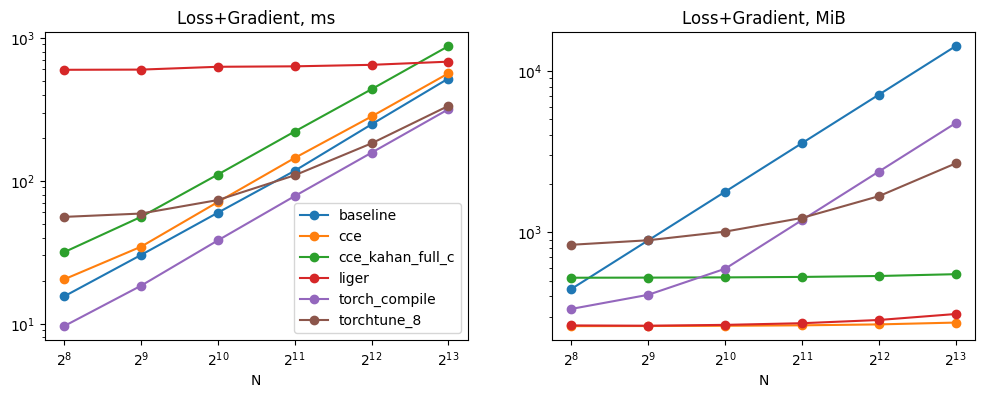

In [16]:
s = summary("scaling", by=("method", "kind", "N"))
display(s)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, d in s.xs("fwbw", level="kind").groupby(level="method"):
    n = d.index.get_level_values("N")
    ax[0].plot(n, d[("runtime_ms", "mean")], "o-", label=m)
    ax[1].plot(n, d[("mem_mib", "mean")], "o-", label=m)
for a, t in zip(ax, ["Loss+Gradient, ms", "Loss+Gradient, MiB"]):
    a.set_xscale("log", base=2); a.set_yscale("log"); a.set_title(t); a.set_xlabel("N")
ax[0].legend(); plt.show()

**Сравнение со статьёй и вывод 1.5.** Loss+Gradient, ms (T4):

| N | CCE | torch.compile | baseline | чанки | Liger | Kahan-FullC |
|---|---|---|---|---|---|---|
| 256 | 20.4 | 9.6 | 15.5 | 55.8 | 597.1 | 31.6 |
| 1 024 | 70.9 | 38.2 | 59.7 | 73.2 | 626.8 | 110.4 |
| 4 096 | 281.5 | 157.0 | 247.9 | 182.5 | 646.8 | 436.7 |
| 8 192 | 563.8 | 316.2 | 518.9 | 333.8 | 680.7 | 874.4 |

| утверждение статьи (из статьи, приложение C.2) | T4 |
|---|---|
| CCE ведёт себя как baseline и torch.compile | рост линейный: время(8192) / время(4096) у CCE 2.00, у baseline 2.09, у torch.compile 2.01; CCE / torch.compile от 1.8 до 2.1 на всём диапазоне |
| у CCE нет накладных расходов чанкинга | да: при N = 256 у чанков 55.8 ms, у CCE 20.4 ms |
| Kahan-FullC медленнее Liger и чанков при большом N и быстрее при малом | да: при N = 256 у FullC 31.6 ms против 55.8 и 597 ms; при N = 8192 у FullC 874 ms против 334 и 681 ms |

1. У CCE нет накладных расходов чанкинга: при N = 256 у чанков 55.8 ms, у CCE 20.4 ms. Liger держится около 600 ms при любом N, потому что число чанков почти всегда 128 (см. 1.4), и каждый чанк обновляет всю матрицу dC.
2. Линейный рост выполнен: время(8192) / время(4096) у CCE 2.00, у baseline 2.09, у torch.compile 2.01.
3. Kahan-FullC быстрее Liger и чанков при малом N (31.6 ms против 55.8 и 597 ms при N = 256) и медленнее при большом (874 ms против 334 и 681 ms при N = 8192): оба критерия выполнены.

Вывод: качественная картина масштабирования воспроизводится полностью. Отличие одно: постоянный множитель около 1.8 между CCE и torch.compile из 1.2.

## 1.6 Отношение |V|/D (таблица A3)

**Статья.** «We find that as the vocabulary size (|V|) to hidden size (D) ratio decreases, CCE’s advantage in computation time for Loss+Gradient decreases, but continues to save a substantial amount of memory.» (раздел 5.1)

**Что делается.** 
1. Эмбеддинги Qwen2.5-0.5B, 1.5B и 3B: словарь один, D = 896, 1536, 2048. Бэкбон нужен только для инференса, 3B считается в fp16.
2. CCE, torch.compile и baseline при N = 8192. Критерий: отношение времени CCE / torch.compile растёт при уменьшении |V|/D.
3. Критерий: память CCE у нижней границы.

In [17]:
!cd $HW2 && $PY -m cce_repro.run vd

===== vd =====
Эмбеддинги: Qwen/Qwen2.5-0.5B-Instruct, 8192 токенов, keep_invalids=False, бэкбон torch.float32
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      fw       198.1 ms       0.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      bw       362.5 ms     274.6 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 cce                      fwbw     567.8 ms     275.3 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            fw       134.9 ms    2374.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            bw       188.9 ms    2374.0 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 torch_compile            fwbw     314.0 ms    4748.1 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 fw       212.5 ms   11870.0 MiB
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 bw         nan ms       nan MiB OOM
   Qwen2.5-0.5B-Instruct rep0 N=8192 baseline                 fwbw       nan ms       nan MiB OOM
   Qwen2.5-0.5B-Instruct rep1 N=819

In [18]:
print(json.load(open(R / "vd" / "models.json")))
display(summary("vd", by=("model", "method", "kind")).unstack("kind"))

{'Qwen/Qwen2.5-0.5B-Instruct': {'V': 151936, 'D': 896, 'V_over_D': 169.57142857142858, 'backbone_dtype': 'torch.float32', 'nonfinite': False}, 'Qwen/Qwen2.5-1.5B-Instruct': {'V': 151936, 'D': 1536, 'V_over_D': 98.91666666666667, 'backbone_dtype': 'torch.float32', 'nonfinite': False}, 'Qwen/Qwen2.5-3B-Instruct': {'V': 151936, 'D': 2048, 'V_over_D': 74.1875, 'backbone_dtype': 'torch.float16', 'nonfinite': False}}


mem_mib                             \
                                            mean                   std        
kind                                          bw       fw    fwbw   bw   fw   
model                      method                                             
Qwen/Qwen2.5-0.5B-Instruct baseline          NaN  11870.0     NaN  NaN  0.0   
                           cce             274.6      0.6   275.3  0.0  0.0   
                           torch_compile  2374.0   2374.1  4748.1  0.0  0.0   
Qwen/Qwen2.5-1.5B-Instruct baseline          NaN  11870.0     NaN  NaN  0.0   
                           cce             469.8      0.6   470.4  0.0  0.0   
                           torch_compile  2374.0   2374.1  4748.1  0.0  0.0   
Qwen/Qwen2.5-3B-Instruct   baseline          NaN  11870.0     NaN  NaN  NaN   
                           cce             626.4      0.6   627.0  0.3  0.0   
                           torch_compile  2374.0   2374.1  4748.1  0.0  0.0   

                                              runtime_ms                       \
                                                    mean                  std   
kind                                     fwbw         bw     fw    fwbw    bw   
model                      method                                               
Qwen/Qwen2.5-0.5B-Instruct baseline       NaN        NaN  213.7     NaN   NaN   
                           cce            0.0      357.2  198.3   557.0   5.0   
                           torch_compile  0.0      188.5  132.9   316.4   1.4   
Qwen/Qwen2.5-1.5B-Instruct baseline       NaN        NaN  304.8     NaN   NaN   
                           cce            0.0      548.1  324.5   851.6   2.5   
                           torch_compile  0.0      325.5  217.6   547.9   2.3   
Qwen/Qwen2.5-3B-Instruct   baseline       NaN        NaN  392.7     NaN   NaN   
                           cce            0.3      733.7  394.3  1107.9  18.2   
                           torch_compile  0.0      424.3  299.9   723.8   5.6   

                                                    
                                                    
kind                                       fw fwbw  
model                      method                   
Qwen/Qwen2.5-0.5B-Instruct baseline       1.2  NaN  
                           cce            1.0  9.3  
                           torch_compile  1.8  4.3  
Qwen/Qwen2.5-1.5B-Instruct baseline       0.5  NaN  
                           cce            8.2  4.6  
                           torch_compile  3.7  0.1  
Qwen/Qwen2.5-3B-Instruct   baseline       NaN  NaN  
                           cce            2.1  3.9  
                           torch_compile  3.3  3.7

**Сравнение со статьёй и вывод 1.6.**

| модель | \|V\| / D | CCE / torch.compile, время Loss+Gradient | память CCE / нижн. граница |
|---|---|---|---|
| Qwen2.5-0.5B (T4) | 170 | 1.76 | 1.006 |
| Qwen2.5-1.5B (T4) | 99 | 1.55 | 1.003 |
| Qwen2.5-3B (T4) | 74 | 1.53 | 1.002 |
| Gemma 2 2B (из статьи) | 111 | 1.01 | - |
| Gemma 2 9B (из статьи) | 71 | 1.01 | - |
| Gemma 2 27B (из статьи) | 56 | 1.10 | - |
| Qwen 2.5 7B (из статьи) | 42 | 1.12 | - |
| Phi 3.5 Mini (из статьи) | 10 | 1.55 | - |

1. Абсолютные значения (T4, ms): CCE 557 / 852 / 1 108, torch.compile 316 / 548 / 724. Baseline в этом эксперименте не поместился в память на backward ни для одной модели: не хватило от 20 до 440 MiB (запрошено 4.64 GiB при 4.21-4.62 GiB свободных). В 1.2 тот же замер занимает 14 244 MiB из 14 912 MiB T4, а здесь в том же процессе перед замером загружается и выгружается бэкбон для эмбеддингов. На критерии это не влияет.
2. Отношение CCE / torch.compile растёт при уменьшении |V|/D: не выполнен, на T4 оно падает (1.76, 1.55, 1.53).

   В статье при |V|/D от 42 до 111 отношение меняется слабо (1.01-1.12), до 1.55 оно доходит только при |V|/D = 10. Диапазон воспроизведения 74-170 лежит там, где эффект статьи почти не виден. Авторы объясняют тренд двумя причинами (приложение C.2, из статьи):
   - число токенов с заметным градиентом примерно постоянно, поэтому при меньшем |V| фильтр отбрасывает меньшую долю;
   - параллелизм CCE равен B x |V| и с ростом D не растёт, а у остальных методов растёт.

   В воспроизведении первой причины нет, потому что словарь один и тот же. Вторая на T4 не работает: при N = 8192 и блоке 64 x 64 ядро CCE запускает 128 x 2 374 = 303 872 блока на 40 SM (расчёт), так что параллелизма хватает при любом D. Остаётся гипотеза: с ростом D у ядер CCE растёт доля матричного умножения на тензорных ядрах относительно постоянных накладных расходов на блок (exp, фильтр, атомарные сложения). Отдельно она не проверялась.
3. Память CCE у нижней границы: выполнен у всех трёх моделей (1.006, 1.003, 1.002).

Вывод: экономия памяти при разных D воспроизводится. Тренд по времени не воспроизводится: в исследованном диапазоне |V|/D статья предсказывает почти постоянное отношение, а на T4 его определяет отставание ядер, а не |V|/D.

## Сохранение результатов

In [19]:
!cd $HW2 && $PY -m cce_repro.run zip

Архив: /kaggle/working/hw2_run/hw2/results_loss_layer.zip


In [ ]:
try:
    from google.colab import files
    files.download(str(RES.parent / "results_loss_layer.zip"))
except ImportError:
    print("Kaggle: файл в", RES.parent / "results_loss_layer.zip")